In [12]:
# Regional Pollution Hotspot Profiles from Satellite-Derived Environmental Features

## 01 - AOD Data Preparation

# This notebook loads and prepares INSAT-3D Aerosol Optical Depth (AOD) data for further analysis.

# Steps:
# 1. Load the HDF5 satellite file
# 2. Inspect the AOD grid
# 3. Extract latitude, longitude, and time
# 4. Convert the AOD grid into individual pixel observations
# 5. Handle missing values
# 6. Examine valid AOD statistics
# 7. save the prepared AOD dataset

In [13]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pathlib as Path
import pathlib
from pathlib import Path


In [14]:
from pathlib import Path

BASE_DIR = Path.cwd().parent
AOD_DIR = BASE_DIR / "data" / "raw" / "AOD"

file_paths = [
    AOD_DIR / "3DIMG_18JUN2024_0530_L2G_AOD_V02R00.h5",
    AOD_DIR / "3DIMG_18JUN2024_0600_L2G_AOD_V02R00.h5",
    AOD_DIR / "3DIMG_18JUN2024_0630_L2G_AOD_V02R00.h5",
    AOD_DIR / "3DIMG_18JUN2024_0700_L2G_AOD_V02R00.h5",
    AOD_DIR / "3DIMG_18JUN2024_0730_L2G_AOD_V02R00.h5",
    AOD_DIR / "3DIMG_18JUN2024_0800_L2G_AOD_V02R00.h5",
    AOD_DIR / "3DIMG_18JUN2024_0830_L2G_AOD_V02R00.h5"
]

In [15]:
all_data = []

for file_path in file_paths:

    with h5py.File(file_path, "r") as f:

        # Read datasets
        aod = f["AOD"][:]
        latitude = f["latitude"][:]
        longitude = f["longitude"][:]
        time_value = f["time"][0]

        # Select the only time slice
        aod_grid = aod[0]

        # Convert -999 fill values to NaN
        aod_grid = np.where(aod_grid == -999, np.nan, aod_grid)

        # Create coordinate grids
        lat_grid, lon_grid = np.meshgrid(
            latitude,
            longitude,
            indexing="ij"
        )

        # Flatten everything using the same ordering
        aod_flat = aod_grid.flatten()
        lat_flat = lat_grid.flatten()
        lon_flat = lon_grid.flatten()

        # Convert satellite time to datetime
        observation_time = (
            pd.Timestamp("2000-01-01")
            + pd.to_timedelta(time_value, unit="m")
        )

        # Create table
        temp_df = pd.DataFrame({
            "latitude": lat_flat,
            "longitude": lon_flat,
            "time": observation_time,
            "AOD": aod_flat
        })

        all_data.append(temp_df)

In [16]:
df_aod = pd.concat(all_data, ignore_index=True)
df_aod.shape
df_aod["time"].value_counts().sort_index()

time
2024-06-18 05:30:00    303601
2024-06-18 06:00:00    303601
2024-06-18 06:30:00    303601
2024-06-18 07:00:00    303601
2024-06-18 07:30:00    303601
2024-06-18 08:00:00    303601
2024-06-18 08:30:00    303601
Name: count, dtype: int64

In [17]:
print(df_aod["AOD"].isnull().sum())
print(df_aod["AOD"].notnull().sum())

1666825
458382


In [18]:
valid_counts = (
    df_aod.dropna(subset=["AOD"])
          .groupby("time")
          .size()
)

valid_counts

time
2024-06-18 05:30:00    69272
2024-06-18 06:00:00    67710
2024-06-18 06:30:00    65727
2024-06-18 07:00:00    65128
2024-06-18 07:30:00    63947
2024-06-18 08:00:00    62771
2024-06-18 08:30:00    63827
dtype: int64

In [19]:
valid_aod_all = df_aod.dropna(subset=["AOD"]).copy()
valid_aod_all["AOD"].describe()

count    458382.000000
mean          0.404039
std           0.387478
min           0.000005
25%           0.145373
50%           0.294162
75%           0.523290
max           2.998972
Name: AOD, dtype: float64

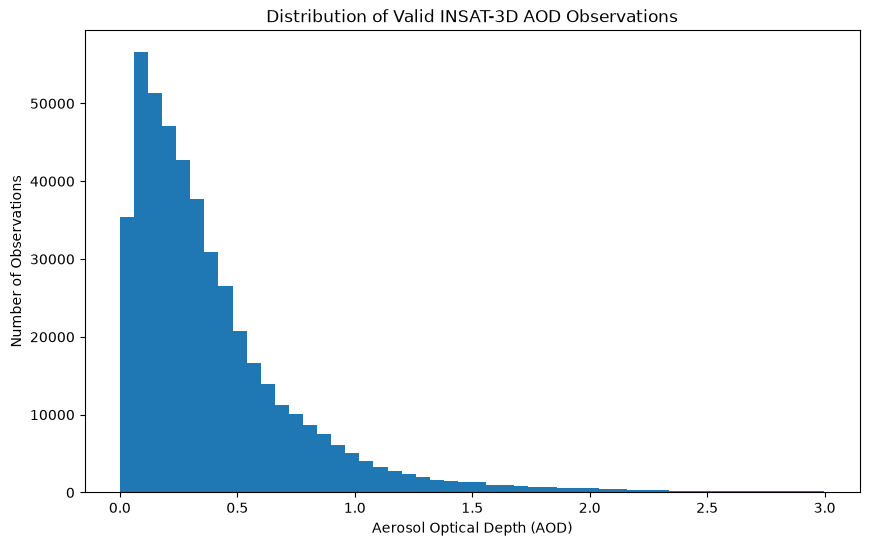

In [20]:
## AOD Distribution

#A histogram is used to examine the distribution of valid Aerosol 
# Optical Depth (AOD) observations and identify skewness and potential 
# extreme values.
plt.figure(figsize=(10, 6))

plt.hist(valid_aod_all["AOD"], bins=50)

plt.xlabel("Aerosol Optical Depth (AOD)")
plt.ylabel("Number of Observations")
plt.title("Distribution of Valid INSAT-3D AOD Observations")

plt.show()

In [21]:
(valid_aod_all["AOD"] < 0).sum()
print(valid_aod_all["AOD"].isna().sum())

0


In [22]:
valid_aod_all.to_csv("aod_prepared.csv", index=False)

In [23]:
print(df_aod.shape)
print(valid_aod_all.shape)
print(valid_counts)

(2125207, 4)
(458382, 4)
time
2024-06-18 05:30:00    69272
2024-06-18 06:00:00    67710
2024-06-18 06:30:00    65727
2024-06-18 07:00:00    65128
2024-06-18 07:30:00    63947
2024-06-18 08:00:00    62771
2024-06-18 08:30:00    63827
dtype: int64
